# Swim probability, oxygen and swim history: fitting the models

Paralysed larval zebrafish; the swim of a fish is recorded from the motor nerve (fictive swimming) while the oxygen level of the water changes (normoxia, then hypoxia).
This notebook fits five models of the probability that a swim starts in a 1 s bin, scores them with cross-validation, and shows the fitted kernels. All the functions are in [`swim_oxygen_models.py`](swim_oxygen_models.py).

## Data 
* 7 recordings, one folder each, in `DATA_ROOT`
* swim data in `data.mat` 
  * `fltCh2`, `back2`: estimated fictive swim signal
  * `swimStartIndT`, `swimEndIndT`: start and end sample of every detected swim
* brain pO2 in `O2_real.mat`
  * `O2_real`: oxygen trace corresponding to the brain pO2 measurement.       
* Sampling rate 6 kHz.

## Steps
1. bin the data (1 s), find the normoxia and hypoxia window of every fish from its oxygen trace;
2. fit the five models by penalised logistic regression (10-fold blocked cross-validation, 5 s purge around the held-out block);
3. held-out R² (against an intercept-only null with one swim rate for both conditions) and AIC;
4. the fitted swim and oxygen kernels.

Next notebook: [`02_free_running_simulation.ipynb`](02_free_running_simulation.ipynb) (uses the fits saved here).

In [1]:
import os
for v in ['OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS']: os.environ[v] = '1'      # one thread per worker process
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import swim_oxygen_models as som

DATA_ROOT = 'figshare/'      # one folder per recording (the data are in the folder figshare/ next to this notebook)
RECORDINGS = ['20220728-fish04', '20220730-fish01-TS2', '20221118-fish01', 'fish01-6dpf', 'fish01-7dpf-grating', 'fish03-7dpf', '20220912-fish02']
N_JOBS = 64                          # parallel workers for the fits
RESULTS_FILE = 'fits.pkl'            # written here, read by the simulation notebook
CC = {'normoxia': '#666666', 'hypoxia': '#99ccff'}
cfg = som.CFG                        # all the settings of the analysis (change them in swim_oxygen_models.Settings)

## 1. Data: 1 s bins, normoxia and hypoxia windows

For every fish (`prepare_fish`):
* **swim label** of a bin = a swim *starts* in it (a swim that starts in the last 20 ms of a bin counts in the next bin); swims shorter than 40 ms are removed;
* **swim input** of a bin = √(summed normalised swim power of the swims that start in it), rescaled per fish;
* **oxygen** = `O2_real` normalised to the mean of minutes 5-10 (= 1), averaged in 1 s bins; the model input is the oxygen z-scored over the two windows of the fish;
* **windows**: the normoxia and the hypoxia period (at most 10 min each) are detected from the oxygen trace.

In [2]:
fishes = [som.prepare_fish(nm, DATA_ROOT + nm, cfg) for nm in RECORDINGS]
rows = []
for f in fishes:
    r = {'fish': f['name']}
    for c in som.CONDITIONS:
        y, idx = f['D'][c]
        r.update({f'{c} window (min)': tuple(round(float(x), 1) for x in f['windows'][c]), f'{c} bins': len(y), f'{c} swim rate': round(float(y.mean()), 3)})
    rows.append(r)
pd.DataFrame(rows).set_index('fish')

,normoxia window (min),normoxia bins,normoxia swim rate,hypoxia window (min),hypoxia bins,hypoxia swim rate
fish,,,,,,
20220728-fish04,"(5.0, 15.0)",851,0.190,"(25.7, 40.0)",857,0.092
20220730-fish01-TS2,"(5.0, 15.0)",721,0.233,"(30.9, 40.0)",669,0.100
20221118-fish01,"(5.0, 15.0)",688,0.148,"(30.2, 40.0)",577,0.036
fish01-6dpf,"(5.0, 20.0)",900,0.926,"(26.6, 40.0)",801,0.508
fish01-7dpf-grating,"(5.0, 15.0)",896,0.487,"(26.7, 40.0)",795,0.079
fish03-7dpf,"(33.3, 43.3)",600,0.173,"(13.3, 23.3)",600,0.092
20220912-fish02,"(8.0, 20.0)",849,0.395,"(30.0, 40.0)",729,0.189


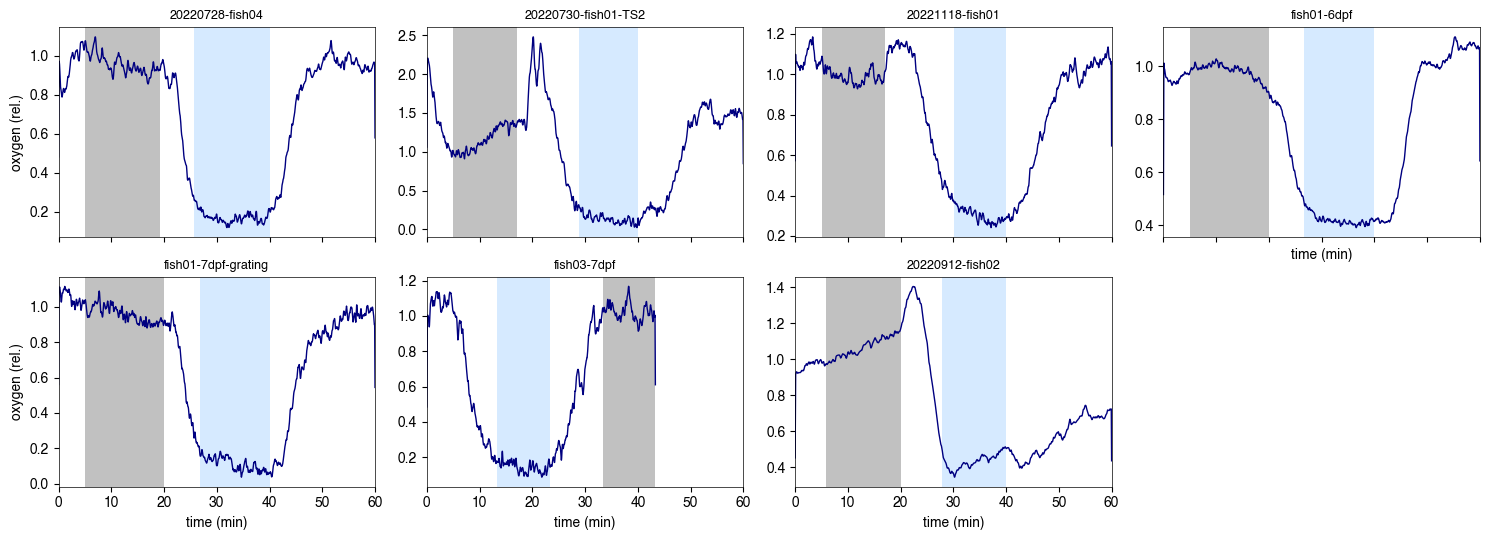

In [3]:
fig, axs = plt.subplots(2, 4, figsize=(15, 5.5), sharex=True); axs = axs.ravel()
for ax, f in zip(axs, fishes):
    t = np.arange(f['n']) / 60
    ax.plot(t, np.convolve(f['o2'], np.ones(10) / 10, mode='same'), color='navy', lw=1)      # oxygen smoothed over 10 s
    for c in som.CONDITIONS:
        ax.axvspan(*f['extra'].get(c, f['windows'][c]), color=CC[c], alpha=0.4, lw=0)      # the time used for the fit of this condition
    ax.set_title(f['name'], fontsize=9); ax.set_xlim(0, 60)
for ax in axs[len(fishes):]: ax.axis('off')
for ax in axs[3:7]: ax.set_xlabel('time (min)')
axs[0].set_ylabel('oxygen (rel.)'); axs[4].set_ylabel('oxygen (rel.)')
plt.tight_layout(); plt.show()

## 2. The five models

The probability of a swim in bin *t* is `sigmoid(η_t)`; η is a sum of an intercept, a *swim kernel* applied to the swim input of the previous `n_lags` = 25 s and an *oxygen kernel* applied to the z-scored oxygen of the current and previous 24 s.

| model | swim kernel | oxygen term | intercept |
|---|---|---|---|
| Current O2 | none | current bin, own weight per condition | shared |
| O2 history | none | lags 0-24, own kernel per condition | shared |
| O2 history + previous swim | previous second only, one weight | own history kernels | shared |
| Swim history | lags 1-25, one kernel for both conditions | none | shared |
| Full model | own kernel per condition | own history kernels | own per condition |


### Cross-validation
10 contiguous blocks per condition; every model is fitted on the other blocks (the 5 bins on each side of the held-out block are dropped) and scored on the held-out block. Every (fish, fold) is one task, and one full-data fit per fish gives the in-sample scores and the AIC.

In [4]:
LF, LFULL = som.run_fits(fishes, cfg, n_jobs=N_JOBS)      # LF[(fish, fold)] = held-out log-likelihoods and fold fits | LFULL[fish] = full-data fits
som.save_results(RESULTS_FILE, cfg, fishes, LF, LFULL)
print(len(LF), 'fold fits and', len(LFULL), 'full-data fits, each for', len(som.MODEL_NAMES), 'models; saved to', RESULTS_FILE)

70 fold fits and 7 full-data fits, each for 5 models; saved to fits.pkl


## 3. R² and AIC

* R² = 1 − log-likelihood(model) / log-likelihood(null)
* The null is an intercept-only model with **one** swim rate for both conditions (the rate of the training bins of the fold for the held-out score, the rate of all the bins for the in-sample score), so a model is credited for the difference of the swim rate between the conditions. 
* AIC = 2·edf − 2·log-likelihood with the effective number of parameters edf = trace[(Z'WZ + P)⁻¹ Z'WZ].

In [5]:
RES = som.score_table(fishes, LF, LFULL, cfg)
tab = RES.groupby('model', sort=False).agg(edf=('edf', 'mean'), R2_in_sample=('r2_in', 'mean'), R2_heldout=('r2_cv', 'mean'), R2_heldout_normoxia=('r2_cv_n', 'mean'),
                                          R2_heldout_hypoxia=('r2_cv_h', 'mean'), AIC_sum=('aic', 'sum'))
tab.rename(index=som.LABELS).round(3)

,edf,R2_in_sample,R2_heldout,R2_heldout_normoxia,R2_heldout_hypoxia,AIC_sum
model,,,,,,
Current O2,2.917,0.088,0.078,0.074,0.110,9339.073
O2 history,2.917,0.088,0.078,0.074,0.110,9339.051
O2 history + previous swim,3.913,0.125,0.116,0.109,0.140,8975.118
Swim history,10.282,0.178,0.166,0.171,0.163,8529.400
Full model,17.493,0.217,0.185,0.185,0.192,8223.977


/tmp/ipykernel_4089858/1681931100.py:22: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[0].legend(frameon=False)


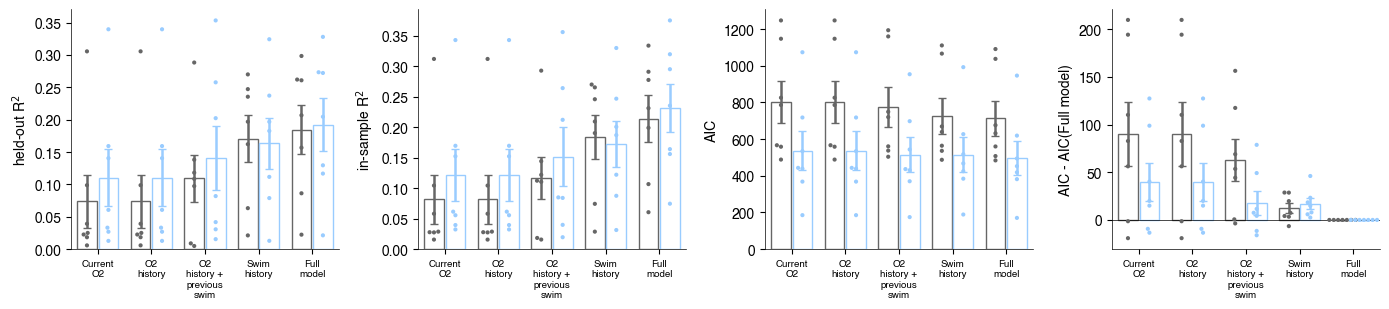

In [6]:
import textwrap
fig, axs = plt.subplots(1, 4, figsize=(14, 3.2)); xs = np.arange(len(som.MODEL_NAMES)); w = 0.4
def panel(ax, col_n, col_h, relative_to_full=False):      # bars = mean +- SEM over the fish, dots = fish (swarm plot), normoxia and hypoxia side by side
    L = []
    for c, col in (('normoxia', col_n), ('hypoxia', col_h)):
        for m in som.MODEL_NAMES:
            v = RES[RES.model == m].set_index('fish')[col]
            if relative_to_full: v = v - RES[RES.model == som.FULL_MODEL].set_index('fish')[col]
            L += [{'model': m, 'condition': c, 'fish': f, 'value': x} for f, x in v.items()]
    L = pd.DataFrame(L)
    for ci, c in enumerate(som.CONDITIONS):
        d = L[L.condition == c].groupby('model').value.agg(['mean', 'sem']).loc[som.MODEL_NAMES]; x = xs + (ci - 0.5) * w
        ax.bar(x, d['mean'], w * 0.92, edgecolor=CC[c], color='none')
        ax.errorbar(x, d['mean'], d['sem'], fmt='none', ecolor=CC[c], capsize=3, elinewidth=1.8)
    sns.swarmplot(data=L, x='model', y='value', hue='condition', order=som.MODEL_NAMES, hue_order=list(som.CONDITIONS), palette=CC, dodge=True, size=3, alpha=1, legend=False, ax=ax)
panel(axs[0], 'r2_cv_n', 'r2_cv_h')      # held-out R2 per condition
panel(axs[1], 'r2_in_n', 'r2_in_h')      # in-sample R2 per condition (fit on all the bins of the fish)
panel(axs[2], 'aic_n', 'aic_h')      # AIC per condition, one value per fish (lower = better; it depends on the number of bins of the fish)
panel(axs[3], 'aic_n', 'aic_h', relative_to_full=True)      # AIC relative to the Full model of the same fish
for ax in axs: ax.set_xlabel(''); ax.set_xticks(xs); ax.set_xticklabels([textwrap.fill(som.LABELS[m], 9) for m in som.MODEL_NAMES], fontsize=7); ax.axhline(0, color='k', lw=0.5); ax.spines[['top', 'right']].set_visible(False)
for ax, yl in zip(axs, ['held-out R$^2$', 'in-sample R$^2$', 'AIC', 'AIC - AIC(Full model)']): ax.set_ylabel(yl)
axs[0].legend(frameon=False)
plt.tight_layout(); plt.show()

In [7]:
# within-subject (repeated-measures) ANOVA over the five models (fish = subjects) for the in-sample R2, the held-out R2 and the AIC, then the paired t-test of every model
# against the Full model (uncorrected). Both conditions together; epsilon / p (Greenhouse-Geisser) = the ANOVA corrected for non-sphericity.
from IPython.display import display
BALANCED = True      # True: both conditions count equally (mean of the two R2; AIC per bin, see score_table) | False: pooled over all the bins of the fish (a condition with more bins counts more)
suffix = '_bal' if BALANCED else ''
METRICS = {'in-sample R2': 'r2_in' + suffix, 'held-out R2': 'r2_cv' + suffix, 'AIC': 'aic' + ('_bal' if BALANCED else '')}
anova_rows, pairs = [], []
for name, col in METRICS.items():
    W = RES.pivot(index='fish', columns='model', values=col)[som.MODEL_NAMES]      # fish x models
    a = som.repeated_measures_anova(W.values)
    anova_rows.append({'metric': name, 'F': a['F'], 'df': f"{a['df1']}, {a['df2']}", 'p': a['p'], 'epsilon': a['epsilon'], 'p (Greenhouse-Geisser)': a['p_gg']})
    t = som.compare_with_reference(W.values, som.MODEL_NAMES, som.FULL_MODEL)[['mean', 'mean - reference', 'p (paired t-test)']]; t.insert(0, 'metric', name); pairs.append(t.rename(index=som.LABELS))
display(pd.DataFrame(anova_rows).set_index('metric').round(4))      # do the models differ?
pd.concat(pairs).reset_index().set_index(['metric', 'model']).round(4)      # every model against the Full model (mean - reference = model minus Full model)

,F,df,p,epsilon,p (Greenhouse-Geisser)
metric,,,,,
in-sample R2,23.9901,"4, 24",0.0,0.3158,0.0010
held-out R2,15.3154,"4, 24",0.0,0.3126,0.0039
AIC,20.5543,"4, 24",0.0,0.3533,0.0010


mean  mean - reference  \
metric       model                                                  
in-sample R2 Current O2                  0.1020           -0.1210   
             O2 history                  0.1020           -0.1210   
             O2 history + previous swim  0.1341           -0.0889   
             Swim history                0.1779           -0.0451   
held-out R2  Current O2                  0.0919           -0.0965   
             O2 history                  0.0919           -0.0965   
             O2 history + previous swim  0.1247           -0.0637   
             Swim history                0.1671           -0.0213   
AIC          Current O2                  0.8672            0.1011   
             O2 history                  0.8672            0.1011   
             O2 history + previous swim  0.8336            0.0675   
             Swim history                0.7942            0.0281   

                                         p (paired t-test)  
metric       model                                          
in-sample R2 Current O2                             0.0010  
             O2 history                             0.0010  
             O2 history + previous swim             0.0015  
             Swim history                           0.0005  
held-out R2  Current O2                             0.0044  
             O2 history                             0.0044  
             O2 history + previous swim             0.0131  
             Swim history                           0.0127  
AIC          Current O2                             0.0012  
             O2 history                             0.0012  
             O2 history + previous swim             0.0054  
             Swim history                           0.0019

## 4. The fitted kernels (Full model)

Weights on the logit scale, from the full-data fit of each fish. Swim kernel: weight of the swim input *k* s earlier (lags 1-25), normalised per fish by its largest absolute weight (the swim input is scaled per fish). Oxygen kernel: weight of the z-scored oxygen *k* s earlier (lags 0-24). Thin lines = fish, thick = mean ± SEM over the fish.

With λ_O2 = 10⁵ the oxygen history (lags ≥ 1) is shrunk to about zero, so the oxygen kernel is its lag-0 weight only (the oxygen of the current bin); this is why *O2 history* and *Current O2* have the same scores above. A smaller λ_O2 in `Settings` lets the history enter.

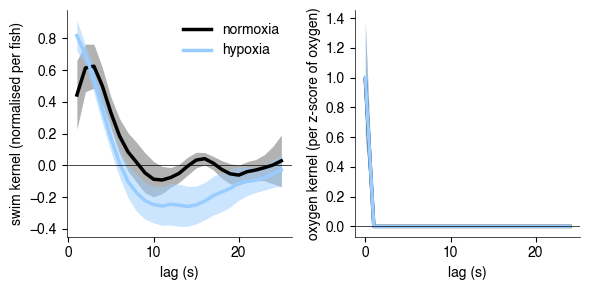

In [9]:
fig, axs = plt.subplots(1, 2, figsize=(6, 3))
for kind, ax in (('swim', axs[0]), ('o2', axs[1])):
    K = {c: [] for c in som.CONDITIONS}
    for i in range(len(fishes)):
        f = LFULL[i][som.FULL_MODEL]; ks = [som.kernels_of(f['w'], f['blocks'], ci) for ci in (0, 1)]
        sc = max(np.abs(ks[0][1]).max(), np.abs(ks[1][1]).max()) if kind == 'swim' else 1.0
        for ci, c in enumerate(som.CONDITIONS): K[c].append((ks[ci][1] if kind == 'swim' else ks[ci][2]) / sc)
    lags = np.arange(1, cfg.n_lags + 1) if kind == 'swim' else np.arange(cfg.n_lags)
    for c in som.CONDITIONS:
        v = np.array(K[c])
        m, se = v.mean(0), v.std(0, ddof=1) / np.sqrt(len(v))
        ax.plot(lags, m, color=CC[c] if c == 'hypoxia' else 'k', lw=2.5, label=c)
        ax.fill_between(lags, m - se, m + se, color=CC[c], alpha=0.5, lw=0)
    ax.axhline(0, color='k', lw=0.5); ax.set_xlabel('lag (s)'); ax.spines[['top', 'right']].set_visible(False)
axs[0].set_ylabel('swim kernel (normalised per fish)'); axs[1].set_ylabel('oxygen kernel (per z-score of oxygen)'); axs[0].legend(frameon=False)
plt.tight_layout(); plt.show()